# Bootstrap: доверительные интервалы для ключевых метрик

**Цель:** заменить точечные оценки на 95% доверительные интервалы
(bootstrap по пользователям) и проверить статистическую значимость
разницы RL vs base для ключевых метрик:
- NDCG@10 (релевантность)
- Judge reward top-10 (независимая вовлечённость)
- RM reward top-10 (оптимизируемая вовлечённость)

**Метод:** paired bootstrap по пользователям, 1000 ресемплов.
Для каждого ресемпла — те же пользователи для base и RL,
считается разница метрик, получается 2.5/50/97.5 перцентили.

### Импорты и пути

In [14]:
import sys
sys.path.append('../src')

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import importlib
import pickle
import time

from tqdm.auto import tqdm

from dataset import build_item_vocab
from model import create_model
from reward_model import create_reward_model
from metrics import build_eval_targets, build_context, ndcg_at_k
from my_evaluate import GPT2Predictor, evaluate_gpt2_fast
from bootstrap import bootstrap_per_target, bootstrap_per_user, paired_bootstrap_per_target, paired_bootstrap_per_user
import judge as judge_mod
importlib.reload(judge_mod)
from judge import JudgeModel

PROC = Path('../data/processed')
RESULTS = Path('../results')
RESULTS_BOOT = RESULTS / 'bootstrap_results'
RESULTS_BOOT.mkdir(exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


### Данные и модели

In [2]:
train_df = pd.read_parquet(PROC / 'train.parquet')
val_df   = pd.read_parquet(PROC / 'val.parquet')
test_df  = pd.read_parquet(PROC / 'test.parquet')

item2idx, idx2item = build_item_vocab(train_df)
vocab_size = len(item2idx) + 2

def load_gpt2_policy(ckpt):
    m = create_model(vocab_size=vocab_size)
    m.load_state_dict(torch.load(ckpt, map_location='cpu'))
    return m

ref_policy = load_gpt2_policy(RESULTS / 'checkpoints_v2' / 'best_model.pt').to(device).eval()
policy_r0 = load_gpt2_policy(RESULTS / 'checkpoints_rl_r0_beta2.0' / 'final_model.pt').to(device).eval()
policy_r3 = load_gpt2_policy(RESULTS / 'checkpoints_rl_r3_lam0.03_beta2.0' / 'final_model.pt').to(device).eval()

# Judge
judge = JudgeModel.load(RESULTS / 'checkpoints_judge' / 'judge')

# RM (для reward)
rm = create_reward_model(vocab_size=vocab_size,
                         init_from=RESULTS / 'checkpoints_v2' / 'best_model.pt')
rm.load_state_dict(torch.load(RESULTS / 'checkpoints_rm_v2' / 'best_model.pt', map_location='cpu'))
rm = rm.to(device).eval()

print("Loaded: base, R0, R3, judge, RM")

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.


[create_reward_model] Backbone: загружено 28 тензоров
[create_reward_model] candidate_emb инициализирован из wte
Loaded: base, R0, R3, judge, RM


### Кэш предсказаний (во избежание пересчёта)

In [3]:
CACHE_PATH = RESULTS_BOOT / 'test_preds_cache.pkl'

if CACHE_PATH.exists():
    print(f"Loading cached predictions from {CACHE_PATH}")
    with open(CACHE_PATH, 'rb') as f:
        cache = pickle.load(f)
    test_preds_base = cache['base']
    test_preds_r0   = cache['r0']
    test_preds_r3   = cache['r3']
else:
    print("Computing predictions (first run, ~10-15 min)...")
    test_targets = build_eval_targets(test_df)
    test_context = build_context(train_df, val_df)

    t0 = time.time()
    print("[base] ...")
    test_preds_base = evaluate_gpt2_fast(
        GPT2Predictor(ref_policy, item2idx, idx2item, max_len=50),
        test_targets, test_context, k=100, batch_size=512, exclude_seen=True,
    )
    print(f"  done in {time.time()-t0:.0f}s")

    t0 = time.time()
    print("[R0] ...")
    test_preds_r0 = evaluate_gpt2_fast(
        GPT2Predictor(policy_r0, item2idx, idx2item, max_len=50),
        test_targets, test_context, k=100, batch_size=512, exclude_seen=True,
    )
    print(f"  done in {time.time()-t0:.0f}s")

    t0 = time.time()
    print("[R3] ...")
    test_preds_r3 = evaluate_gpt2_fast(
        GPT2Predictor(policy_r3, item2idx, idx2item, max_len=50),
        test_targets, test_context, k=100, batch_size=512, exclude_seen=True,
    )
    print(f"  done in {time.time()-t0:.0f}s")

    with open(CACHE_PATH, 'wb') as f:
        pickle.dump({'base': test_preds_base, 'r0': test_preds_r0, 'r3': test_preds_r3}, f)
    print(f"Cached to {CACHE_PATH}")

# Множество общих пользователей
common_users = sorted(set(test_preds_base) & set(test_preds_r0) & set(test_preds_r3))
print(f"Common users with predictions: {len(common_users):,}")

Computing predictions (first run, ~10-15 min)...
[base] ...
Уникальных юзеров для оценки: 132,323


predict_batch:   0%|          | 0/259 [00:00<?, ?it/s]

  done in 39s
[R0] ...
Уникальных юзеров для оценки: 132,323


predict_batch:   0%|          | 0/259 [00:00<?, ?it/s]

  done in 40s
[R3] ...
Уникальных юзеров для оценки: 132,323


predict_batch:   0%|          | 0/259 [00:00<?, ?it/s]

  done in 39s
Cached to ..\results\bootstrap_results\test_preds_cache.pkl
Common users with predictions: 132,323


### Подготовка per-target и per-user метрик

In [4]:
test_targets = build_eval_targets(test_df)
user_targets = test_targets.groupby('user_id')['item_id'].apply(list).to_dict()

def per_user_ndcg(preds_dict, targets_dict, K=10):
    """
    Returns: dict {user_id: np.array([ndcg для каждого таргета])}
    """
    result = {}
    for u, items in preds_dict.items():
        targets = targets_dict.get(u, [])
        if not targets:
            continue
        topk = items[:K]
        vals = np.array([ndcg_at_k(topk, t, K) for t in targets], dtype=np.float32)
        result[u] = vals
    return result

def per_user_scores(preds_dict, score_fn, K=10):
    result = {}
    for u, items in preds_dict.items():
        topk = items[:K]
        if not topk:
            continue
        result[u] = float(np.mean(score_fn(u, topk)))
    return result

print("Preparing per-user metrics...")
t0 = time.time()

# NDCG@10 per-target (по каждому таргету отдельно)
ndcg_base = per_user_ndcg(test_preds_base, user_targets)
ndcg_r0   = per_user_ndcg(test_preds_r0,   user_targets)
ndcg_r3   = per_user_ndcg(test_preds_r3,   user_targets)
print(f"  NDCG@10: {time.time()-t0:.0f}s")

# Judge reward per-user
t0 = time.time()
def judge_score(u, items):
    return judge.predict(np.array([u]*len(items)), np.array(items))

judge_base = per_user_scores(test_preds_base, judge_score)
judge_r0   = per_user_scores(test_preds_r0,   judge_score)
judge_r3   = per_user_scores(test_preds_r3,   judge_score)
print(f"  Judge reward: {time.time()-t0:.0f}s")

print("Done")

Preparing per-user metrics...
  NDCG@10: 1s
  Judge reward: 1667s
Done


### Bootstrap NDCG@10

In [12]:
N_SAMPLES = 1000

print(f"Bootstrap NDCG@10 ({N_SAMPLES} samples)...")
t0 = time.time()

ndcg_base_pt, ndcg_base_ci = bootstrap_per_target(ndcg_base, n_samples=N_SAMPLES)
ndcg_r0_pt,   ndcg_r0_ci   = bootstrap_per_target(ndcg_r0,   n_samples=N_SAMPLES)
ndcg_r3_pt,   ndcg_r3_ci   = bootstrap_per_target(ndcg_r3,   n_samples=N_SAMPLES)

ndcg_r0_d, ndcg_r0_dci = paired_bootstrap_per_target(ndcg_r0, ndcg_base, n_samples=N_SAMPLES)
ndcg_r3_d, ndcg_r3_dci = paired_bootstrap_per_target(ndcg_r3, ndcg_base, n_samples=N_SAMPLES)

print(f"  done in {time.time()-t0:.0f}s\n")

print(f"{'Model':<10} {'NDCG@10':>10}   {'95% CI':>24}")
print("-" * 50)
print(f"{'base':<10} {ndcg_base_pt:>10.4f}   [{ndcg_base_ci[0]:.4f}, {ndcg_base_ci[1]:.4f}]")
print(f"{'R0':<10} {ndcg_r0_pt:>10.4f}   [{ndcg_r0_ci[0]:.4f}, {ndcg_r0_ci[1]:.4f}]")
print(f"{'R3':<10} {ndcg_r3_pt:>10.4f}   [{ndcg_r3_ci[0]:.4f}, {ndcg_r3_ci[1]:.4f}]")

print(f"\n{'Comparison':<15} {'Δ':>10}   {'95% CI (paired)':>24}")
print("-" * 50)
print(f"{'R0 - base':<15} {ndcg_r0_d:>+10.4f}   [{ndcg_r0_dci[0]:+.4f}, {ndcg_r0_dci[1]:+.4f}]")
print(f"{'R3 - base':<15} {ndcg_r3_d:>+10.4f}   [{ndcg_r3_dci[0]:+.4f}, {ndcg_r3_dci[1]:+.4f}]")

Bootstrap NDCG@10 (1000 samples)...
  done in 803s

Model         NDCG@10                     95% CI
--------------------------------------------------
base           0.1304   [0.1292, 0.1317]
R0             0.1290   [0.1278, 0.1303]
R3             0.1301   [0.1288, 0.1313]

Comparison               Δ            95% CI (paired)
--------------------------------------------------
R0 - base          -0.0014   [-0.0018, -0.0011]
R3 - base          -0.0004   [-0.0007, -0.0000]


### Bootstrap Judge reward

In [15]:
print(f"Bootstrap Judge reward top-10 ({N_SAMPLES} samples)...")
t0 = time.time()

judge_base_pt, judge_base_ci = bootstrap_per_user(judge_base, n_samples=N_SAMPLES)
judge_r0_pt,   judge_r0_ci   = bootstrap_per_user(judge_r0,   n_samples=N_SAMPLES)
judge_r3_pt,   judge_r3_ci   = bootstrap_per_user(judge_r3,   n_samples=N_SAMPLES)

judge_r0_d, judge_r0_dci = paired_bootstrap_per_user(judge_r0, judge_base, n_samples=N_SAMPLES)
judge_r3_d, judge_r3_dci = paired_bootstrap_per_user(judge_r3, judge_base, n_samples=N_SAMPLES)

print(f"  done in {time.time()-t0:.0f}s\n")

print(f"{'Model':<10} {'Judge R':>10}   {'95% CI':>24}")
print("-" * 50)
print(f"{'base':<10} {judge_base_pt:>10.4f}   [{judge_base_ci[0]:.4f}, {judge_base_ci[1]:.4f}]")
print(f"{'R0':<10} {judge_r0_pt:>10.4f}   [{judge_r0_ci[0]:.4f}, {judge_r0_ci[1]:.4f}]")
print(f"{'R3':<10} {judge_r3_pt:>10.4f}   [{judge_r3_ci[0]:.4f}, {judge_r3_ci[1]:.4f}]")

print(f"\n{'Comparison':<15} {'Δ':>10}   {'95% CI (paired)':>24}")
print("-" * 50)
print(f"{'R0 - base':<15} {judge_r0_d:>+10.4f}   [{judge_r0_dci[0]:+.4f}, {judge_r0_dci[1]:+.4f}]")
print(f"{'R3 - base':<15} {judge_r3_d:>+10.4f}   [{judge_r3_dci[0]:+.4f}, {judge_r3_dci[1]:+.4f}]")

Bootstrap Judge reward top-10 (1000 samples)...
  done in 7s

Model         Judge R                     95% CI
--------------------------------------------------
base           0.4817   [0.4803, 0.4829]
R0             0.5069   [0.5055, 0.5081]
R3             0.5036   [0.5022, 0.5048]

Comparison               Δ            95% CI (paired)
--------------------------------------------------
R0 - base          +0.0252   [+0.0251, +0.0254]
R3 - base          +0.0219   [+0.0217, +0.0220]


### Bootstrap RM reward top-10

In [16]:
print(f"Bootstrap RM reward top-10 ({N_SAMPLES} samples)...")

from reward_functions import RMReward, build_item_mean_map
from rm_index import RMIndex

@torch.no_grad()
def rm_score_topk(contexts, items_list, rm, item2idx, max_len=50, device='cuda'):
    """Score top-k items for each context via RM."""
    B = len(contexts)
    K = len(items_list[0])
    ctx_input = torch.zeros(B, max_len - 1, dtype=torch.long, device=device)
    for i, ctx in enumerate(contexts):
        recent = ctx[-(max_len - 1):] if ctx else []
        indexed = [item2idx.get(int(x), 1) for x in recent]
        if indexed:
            ctx_input[i, -len(indexed):] = torch.tensor(indexed, device=device)
    cand = torch.zeros(B, K, dtype=torch.long, device=device)
    for i, items in enumerate(items_list):
        for j, it in enumerate(items[:K]):
            cand[i, j] = item2idx.get(int(it), 1)
    # forward
    h = ctx_input.unsqueeze(1).expand(-1, K, -1)  # (B, K, L-1)
    c = cand.unsqueeze(2)                         # (B, K, 1)
    seq = torch.cat([h, c], dim=2).reshape(B * K, max_len)
    with torch.no_grad():
        scores = torch.sigmoid(rm(seq)).reshape(B, K)
    return scores.cpu().numpy()

# Загружаем test_context один раз
test_context = build_context(train_df, val_df)

def rm_reward_per_user(preds_dict, context_dict, rm, item2idx, K=10, batch_size=256):
    users = list(preds_dict.keys())
    result = {}
    for start in tqdm(range(0, len(users), batch_size), desc="RM reward"):
        batch = users[start:start + batch_size]
        ctxs = [context_dict.get(u, {}).get('items', []) for u in batch]
        items = [preds_dict[u][:K] for u in batch]
        scores = rm_score_topk(ctxs, items, rm, item2idx)
        for u, row in zip(batch, scores):
            result[u] = float(row.mean())
    return result

t0 = time.time()
rm_base = rm_reward_per_user(test_preds_base, test_context, rm, item2idx)
rm_r0   = rm_reward_per_user(test_preds_r0,   test_context, rm, item2idx)
rm_r3   = rm_reward_per_user(test_preds_r3,   test_context, rm, item2idx)
print(f"  RM scoring done in {time.time()-t0:.0f}s")

rm_base_pt, rm_base_ci = bootstrap_per_user(rm_base, n_samples=N_SAMPLES)
rm_r0_pt,   rm_r0_ci   = bootstrap_per_user(rm_r0,   n_samples=N_SAMPLES)
rm_r3_pt,   rm_r3_ci   = bootstrap_per_user(rm_r3,   n_samples=N_SAMPLES)

rm_r0_d, rm_r0_dci = paired_bootstrap_per_user(rm_r0, rm_base, n_samples=N_SAMPLES)
rm_r3_d, rm_r3_dci = paired_bootstrap_per_user(rm_r3, rm_base, n_samples=N_SAMPLES)

print(f"\n{'Model':<10} {'RM R':>10}   {'95% CI':>24}")
print("-" * 50)
print(f"{'base':<10} {rm_base_pt:>10.4f}   [{rm_base_ci[0]:.4f}, {rm_base_ci[1]:.4f}]")
print(f"{'R0':<10} {rm_r0_pt:>10.4f}   [{rm_r0_ci[0]:.4f}, {rm_r0_ci[1]:.4f}]")
print(f"{'R3':<10} {rm_r3_pt:>10.4f}   [{rm_r3_ci[0]:.4f}, {rm_r3_ci[1]:.4f}]")

print(f"\n{'Comparison':<15} {'Δ':>10}   {'95% CI (paired)':>24}")
print("-" * 50)
print(f"{'R0 - base':<15} {rm_r0_d:>+10.4f}   [{rm_r0_dci[0]:+.4f}, {rm_r0_dci[1]:+.4f}]")
print(f"{'R3 - base':<15} {rm_r3_d:>+10.4f}   [{rm_r3_dci[0]:+.4f}, {rm_r3_dci[1]:+.4f}]")

Bootstrap RM reward top-10 (1000 samples)...


RM reward:   0%|          | 0/517 [00:00<?, ?it/s]

RM reward:   0%|          | 0/517 [00:00<?, ?it/s]

RM reward:   0%|          | 0/517 [00:00<?, ?it/s]

  RM scoring done in 245s

Model            RM R                     95% CI
--------------------------------------------------
base           0.5092   [0.5087, 0.5098]
R0             0.5502   [0.5497, 0.5508]
R3             0.5444   [0.5439, 0.5450]

Comparison               Δ            95% CI (paired)
--------------------------------------------------
R0 - base          +0.0410   [+0.0408, +0.0412]
R3 - base          +0.0352   [+0.0350, +0.0354]


### Визуализация CIs

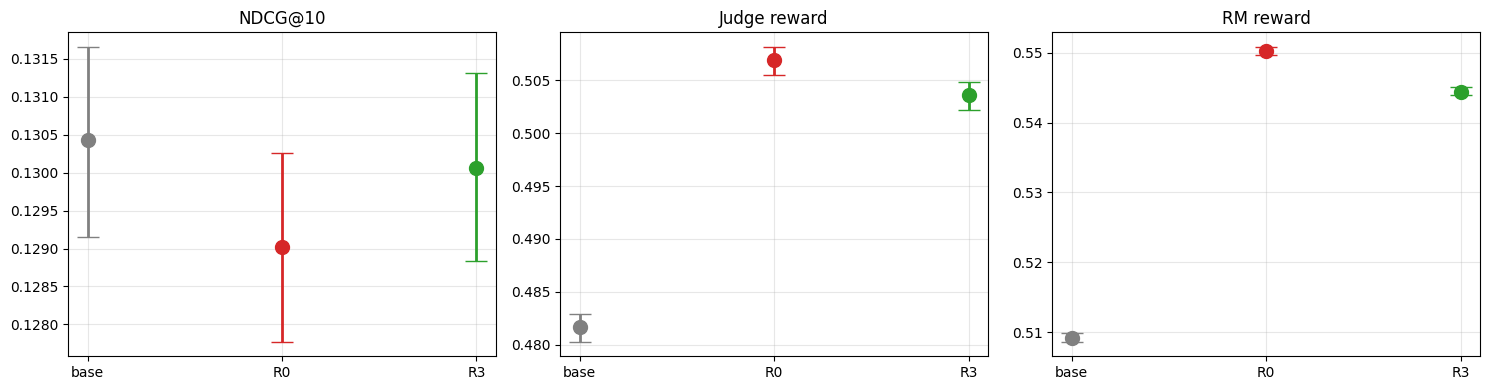

Saved: ..\results\bootstrap_results\bootstrap_cis.png


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics_plot = [
    ('NDCG@10',     ndcg_base_pt,  ndcg_base_ci,  ndcg_r0_pt,  ndcg_r0_ci,  ndcg_r3_pt,  ndcg_r3_ci),
    ('Judge reward', judge_base_pt, judge_base_ci, judge_r0_pt, judge_r0_ci, judge_r3_pt, judge_r3_ci),
    ('RM reward',   rm_base_pt,    rm_base_ci,    rm_r0_pt,    rm_r0_ci,    rm_r3_pt,    rm_r3_ci),
]

for ax, (name, b_pt, b_ci, r0_pt, r0_ci, r3_pt, r3_ci) in zip(axes, metrics_plot):
    xs = [0, 1, 2]
    pts = [b_pt, r0_pt, r3_pt]
    los = [b_pt - b_ci[0],  r0_pt - r0_ci[0],  r3_pt - r3_ci[0]]
    his = [b_ci[1] - b_pt,  r0_ci[1] - r0_pt,  r3_ci[1] - r3_pt]
    colors = ['gray', '#d62728', '#2ca02c']

    for x, pt, lo, hi, color in zip(xs, pts, los, his, colors):
        ax.errorbar(
            x, pt, yerr=[[lo], [hi]],
            fmt='o', capsize=8, markersize=10,
            color=color, ecolor=color, elinewidth=2, zorder=5,
        )

    ax.set_xticks(xs)
    ax.set_xticklabels(['base', 'R0', 'R3'])
    ax.set_title(name)
    ax.grid(alpha=0.3)

plt.tight_layout()
out_path = RESULTS_BOOT / 'bootstrap_cis.png'
plt.savefig(out_path, dpi=130, bbox_inches='tight')
plt.show()
print(f"Saved: {out_path}")

### Сохранение результатов

In [19]:
rows = []

# NDCG
rows.append({
    'metric': 'NDCG@10',
    'base': ndcg_base_pt, 'base_lo': ndcg_base_ci[0], 'base_hi': ndcg_base_ci[1],
    'r0':   ndcg_r0_pt,   'r0_lo':   ndcg_r0_ci[0],   'r0_hi':   ndcg_r0_ci[1],
    'r3':   ndcg_r3_pt,   'r3_lo':   ndcg_r3_ci[0],   'r3_hi':   ndcg_r3_ci[1],
    'r0_minus_base':    ndcg_r0_d, 'r0_diff_lo': ndcg_r0_dci[0], 'r0_diff_hi': ndcg_r0_dci[1],
    'r3_minus_base':    ndcg_r3_d, 'r3_diff_lo': ndcg_r3_dci[0], 'r3_diff_hi': ndcg_r3_dci[1],
})

# Judge
rows.append({
    'metric': 'Judge_reward_top10',
    'base': judge_base_pt, 'base_lo': judge_base_ci[0], 'base_hi': judge_base_ci[1],
    'r0':   judge_r0_pt,   'r0_lo':   judge_r0_ci[0],   'r0_hi':   judge_r0_ci[1],
    'r3':   judge_r3_pt,   'r3_lo':   judge_r3_ci[0],   'r3_hi':   judge_r3_ci[1],
    'r0_minus_base':    judge_r0_d, 'r0_diff_lo': judge_r0_dci[0], 'r0_diff_hi': judge_r0_dci[1],
    'r3_minus_base':    judge_r3_d, 'r3_diff_lo': judge_r3_dci[0], 'r3_diff_hi': judge_r3_dci[1],
})

# RM
rows.append({
    'metric': 'RM_reward_top10',
    'base': rm_base_pt, 'base_lo': rm_base_ci[0], 'base_hi': rm_base_ci[1],
    'r0':   rm_r0_pt,   'r0_lo':   rm_r0_ci[0],   'r0_hi':   rm_r0_ci[1],
    'r3':   rm_r3_pt,   'r3_lo':   rm_r3_ci[0],   'r3_hi':   rm_r3_ci[1],
    'r0_minus_base':    rm_r0_d, 'r0_diff_lo': rm_r0_dci[0], 'r0_diff_hi': rm_r0_dci[1],
    'r3_minus_base':    rm_r3_d, 'r3_diff_lo': rm_r3_dci[0], 'r3_diff_hi': rm_r3_dci[1],
})

df = pd.DataFrame(rows)
df.to_csv(RESULTS_BOOT / 'bootstrap_summary.csv', index=False)
print(f"Saved: {RESULTS_BOOT / 'bootstrap_summary.csv'}")
print("\nSummary:")
print(df[['metric', 'r0_minus_base', 'r0_diff_lo', 'r0_diff_hi',
          'r3_minus_base', 'r3_diff_lo', 'r3_diff_hi']].to_string(index=False))

Saved: ..\results\bootstrap_results\bootstrap_summary.csv

Summary:
            metric  r0_minus_base  r0_diff_lo  r0_diff_hi  r3_minus_base  r3_diff_lo  r3_diff_hi
           NDCG@10      -0.001408   -0.001761   -0.001055      -0.000361   -0.000703   -0.000026
Judge_reward_top10       0.025238    0.025069    0.025390       0.021890    0.021735    0.022044
   RM_reward_top10       0.040973    0.040761    0.041161       0.035192    0.034995    0.035378
